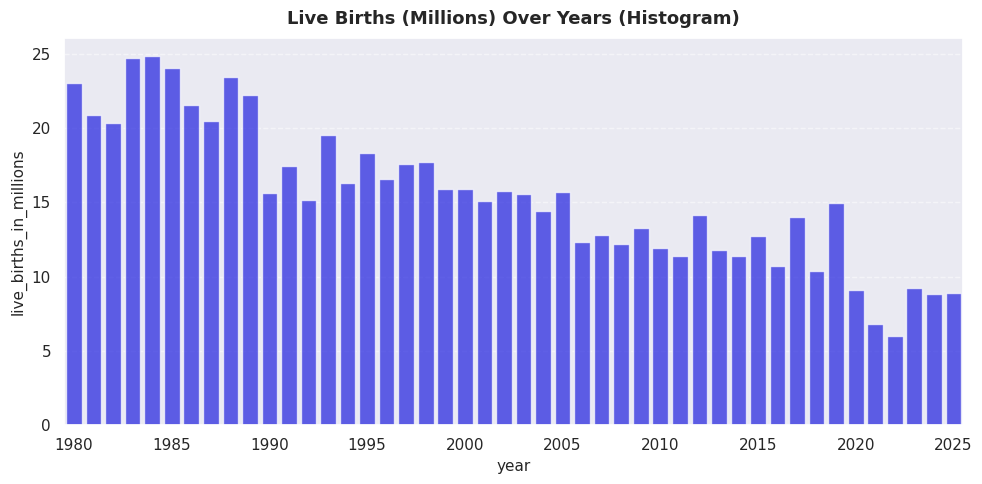

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(color_codes=True)
sns.set_palette(sns.color_palette('muted'))

df = pd.read_csv("china_childbirth_statistics_1950_2025.csv")
df_filtered = df.loc[df['year'] >= 1980].copy()

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(x="year", y="live_births_in_millions", data=df_filtered, ax=ax, color="blue", alpha=0.7)

ax.set_title("Live Births (Millions) Over Years (Histogram)", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("year", fontsize=11)
ax.set_ylabel("live_births_in_millions", fontsize=11)

plt.xticks(ticks=range(0, len(df_filtered), 5), labels=df_filtered['year'].iloc[::5], rotation=0)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

fig.tight_layout()
plt.show()

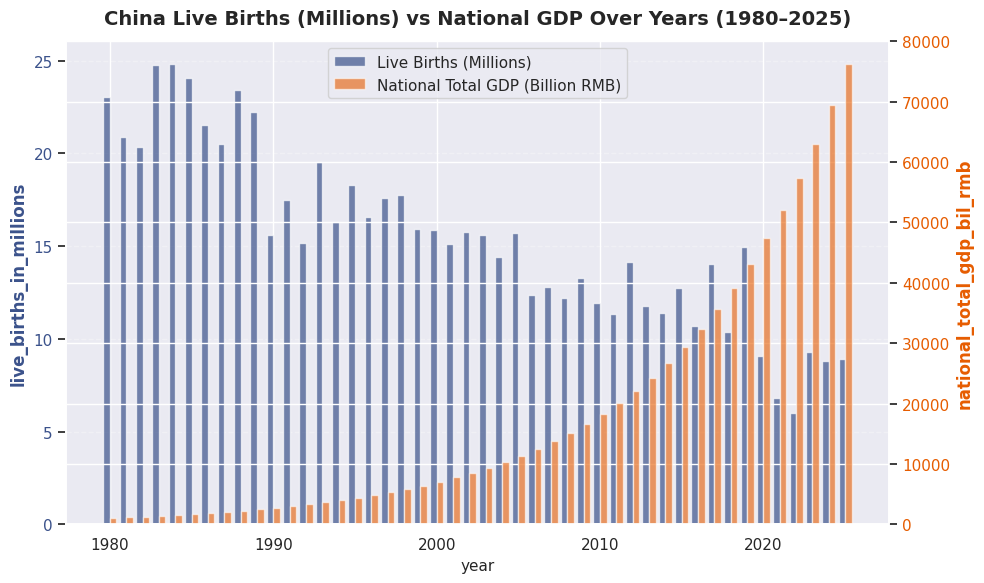

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(color_codes=True)
sns.set_palette(sns.color_palette('muted'))

df_births = pd.read_csv("china_childbirth_statistics_1950_2025.csv")
df_gdp = pd.read_csv("china_rich_provinces_gdp_1950_2025.csv")

df_merged = pd.merge(df_births, df_gdp[['year', 'national_total_gdp_bil_rmb']], on='year')
df_filtered = df_merged.loc[df_merged['year'] >= 1980].copy()

fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = '#3b528b'
ax1.bar(df_filtered['year'] - 0.2, df_filtered['live_births_in_millions'], width=0.4, color=color1, alpha=0.7, label='Live Births (Millions)')
ax1.set_xlabel('year', fontsize=11)
ax1.set_ylabel('live_births_in_millions', color=color1, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = '#e65c00'
ax2.bar(df_filtered['year'] + 0.2, df_filtered['national_total_gdp_bil_rmb'], width=0.4, color=color2, alpha=0.6, label='National Total GDP (Billion RMB)')
ax2.set_ylabel('national_total_gdp_bil_rmb', color=color2, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('China Live Births (Millions) vs National GDP Over Years (1980–2025)', fontsize=14, fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.3, axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', frameon=True)

fig.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

df_births = pd.read_csv("china_childbirth_statistics_1950_2025.csv")
df_gdp = pd.read_csv("china_rich_provinces_gdp_1950_2025.csv")

df_merged = pd.merge(df_births, df_gdp, on='year')

df_filtered = df_merged.loc[df_merged['year'] >= 1950].copy()

df_filtered['birth_change'] = df_filtered['total_live_births'].diff()
df_filtered['target'] = (df_filtered['birth_change'] > 0).astype(int)

df_filtered['prev_births'] = df_filtered['live_births_in_millions'].shift(1)
df_filtered['prev_gdp'] = df_filtered['national_total_gdp_bil_rmb'].shift(1)
df_filtered['prev_tfr'] = df_filtered['total_fertility_rate'].shift(1)

df_model = df_filtered.dropna().copy()

features = ['prev_births', 'prev_gdp', 'prev_tfr', 'guangdong_gdp_bil_rmb', 'jiangsu_gdp_bil_rmb']
X = df_model[features]
y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print(f"Dataset rows being analyzed: {len(df_model)}")
print(f"Model Accuracy (from 1950+ data): {accuracy_score(y_test, predictions) * 100:.2f}%\n")

print("Test Set Predictions:")
for year, pred, actual in zip(df_model.loc[y_test.index, 'year'], predictions, y_test):
    direction = "UP ^" if pred == 1 else "DOWN v"
    actual_dir = "UP ^" if actual == 1 else "DOWN v"
    print(f"Year {year} | Predicted: {direction} | Actual: {actual_dir}")

Dataset rows being analyzed: 75
Model Accuracy (from 1950+ data): 60.00%

Test Set Predictions:
Year 2011 | Predicted: DOWN v | Actual: DOWN v
Year 2012 | Predicted: DOWN v | Actual: UP ^
Year 2013 | Predicted: DOWN v | Actual: DOWN v
Year 2014 | Predicted: DOWN v | Actual: DOWN v
Year 2015 | Predicted: DOWN v | Actual: UP ^
Year 2016 | Predicted: DOWN v | Actual: DOWN v
Year 2017 | Predicted: DOWN v | Actual: UP ^
Year 2018 | Predicted: DOWN v | Actual: DOWN v
Year 2019 | Predicted: DOWN v | Actual: UP ^
Year 2020 | Predicted: DOWN v | Actual: DOWN v
Year 2021 | Predicted: DOWN v | Actual: DOWN v
Year 2022 | Predicted: DOWN v | Actual: DOWN v
Year 2023 | Predicted: DOWN v | Actual: UP ^
Year 2024 | Predicted: DOWN v | Actual: DOWN v
Year 2025 | Predicted: DOWN v | Actual: UP ^


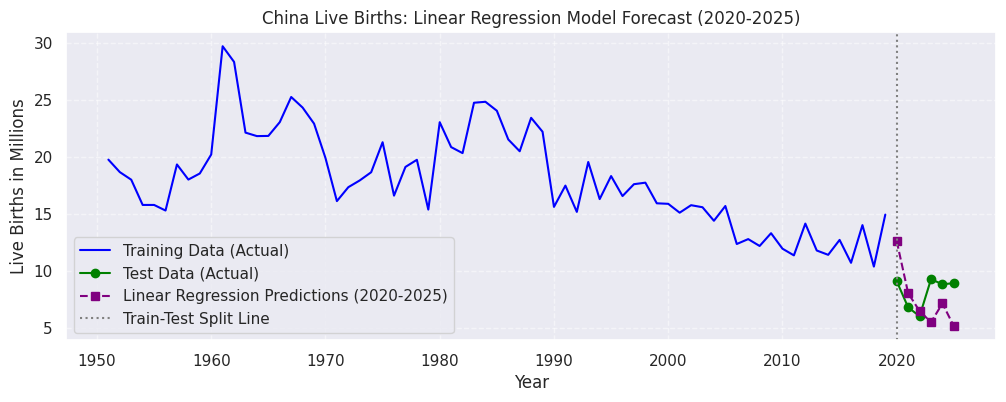

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Load data
df_births = pd.read_csv('china_childbirth_statistics_1950_2025.csv')
df_gdp = pd.read_csv('china_rich_provinces_gdp_1950_2025.csv')
df_merged = pd.merge(df_births, df_gdp, on='year')

# Prepare features
df_merged['prev_births'] = df_merged['live_births_in_millions'].shift(1)
df_merged['prev_gdp'] = df_merged['national_total_gdp_bil_rmb'].shift(1)
df_merged['prev_tfr'] = df_merged['total_fertility_rate'].shift(1)

df_model = df_merged.dropna().copy()

features = ['prev_births', 'prev_gdp', 'prev_tfr', 'guangdong_gdp_bil_rmb', 'jiangsu_gdp_bil_rmb']

# Split training (1950-2019) and testing (2020-2025)
train_df = df_model[df_model['year'] < 2020]
test_df = df_model[df_model['year'] >= 2020]

X_train = train_df[features]
y_train = train_df['live_births_in_millions']

X_test = test_df[features]
y_test = test_df['live_births_in_millions']

# Fit Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on the test set
lr_predictions = lr_model.predict(X_test)

# Plot actuals and linear regression predictions
plt.figure(figsize=(12, 4))
plt.plot(train_df['year'], train_df['live_births_in_millions'], label='Training Data (Actual)', color='blue')
plt.plot(test_df['year'], y_test, label='Test Data (Actual)', color='green', marker='o')
plt.plot(test_df['year'], lr_predictions, label='Linear Regression Predictions (2020-2025)', color='purple', linestyle='--', marker='s')
plt.axvline(x=2020, color='gray', linestyle=':', label='Train-Test Split Line')
plt.title('China Live Births: Linear Regression Model Forecast (2020-2025)')
plt.xlabel('Year')
plt.ylabel('Live Births in Millions')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Load Data
df_births = pd.read_csv('china_childbirth_statistics_1950_2025.csv')
df_gdp = pd.read_csv('china_rich_provinces_gdp_1950_2025.csv')
df_merged = pd.merge(df_births, df_gdp, on='year')

# Prepare Features
df_merged['prev_births'] = df_merged['live_births_in_millions'].shift(1)
df_merged['prev_gdp'] = df_merged['national_total_gdp_bil_rmb'].shift(1)
df_merged['prev_tfr'] = df_merged['total_fertility_rate'].shift(1)

df_model = df_merged.dropna().copy()

features = ['prev_births', 'prev_gdp', 'prev_tfr', 'guangdong_gdp_bil_rmb', 'jiangsu_gdp_bil_rmb']

# Split training data (1950-2020) and test data (2020-2025)
train_df = df_model[df_model['year'] < 2020]
test_df = df_model[df_model['year'] >= 2020]

X_train = train_df[features]
y_train = train_df['live_births_in_millions']
X_test = test_df[features]
y_test = test_df['live_births_in_millions']

# Train Linear Regression Model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict
lr_pred = lr.predict(X_test)

# Create DataFrame
df_pred = pd.DataFrame({'year': test_df['year'],'actual_births': y_test,'predicted_births': lr_pred})

display(df_pred)

,year,actual_births,predicted_births
70,2020,9.089,12.604457
71,2021,6.795,8.042642
72,2022,6.022,6.471920
73,2023,9.262,5.494698
74,2024,8.827,7.140951
75,2025,8.916,5.140293
